# Introducción a QuTiP con el VdP cuántico

**QuTiP** (*Quantum Toolbox in Python*) resuelve numéricamente sistemas cuánticos abiertos: construye operadores truncados, el Liouvilliano, el estado estacionario, la evolución temporal y las correlaciones a dos tiempos. Este cuaderno lo presenta con el modelo del TFM y comprueba cada paso contra lo que ya sale en Mathematica.

Los convenios son los de `RepresentacionFase.wl`:

- $\hbar = 1$ y $\mathcal{D}[L]\rho = L\rho L^\dagger - \tfrac12\{L^\dagger L, \rho\}$, con la tasa fuera de $L$.
- Se trunca a $d$ niveles $|0\rangle \dots |d-1\rangle$, y los productos se hacen con las matrices ya truncadas.
- $\mathrm{vec}(\rho)$ apila columnas.

El modelo:

$$\dot\rho = -i[H,\rho] + \kappa_p\,\mathcal{D}[a^\dagger]\rho + \kappa_m\,\mathcal{D}[a^2]\rho, \qquad H = \Delta\, a^\dagger a + \frac{\mathcal{E}}{2}(a + a^\dagger)$$

con $r = \kappa_p/\kappa_m$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

print("QuTiP", qt.__version__)

QuTiP 5.3.1


## 1. Objetos: `Qobj`

Todo en QuTiP es un `Qobj`: kets, bras, operadores y superoperadores. Guarda la matriz (dispersa) y sus dimensiones. `qt.destroy(d)` es $a$ truncado a $d$ niveles, como `matrizFock[a, d]`.

El truncado se nota en el conmutador: $[a, a^\dagger] = 1$ salvo en $|d-1\rangle$, donde vale $-(d-1)$. Es lo mismo que en el paquete de Mathematica (allí $a a^\dagger = 0$ en $|d-1\rangle$).

In [2]:
d = 4
a = qt.destroy(d)
ad = a.dag()

print(a)
print("[a, a†] =", np.diag((a * ad - ad * a).full()).real)

# kets, matrices densidad y valores esperados
psi = (qt.basis(d, 0) + qt.basis(d, 1)).unit()
rho = qt.ket2dm(psi)
print("<n> =", qt.expect(ad * a, rho), "  <a> =", qt.expect(a, rho))

Quantum object: dims=[[4], [4]], shape=(4, 4), type='oper', dtype=Dia, isherm=False
Qobj data =
[[0.         1.         0.         0.        ]
 [0.         0.         1.41421356 0.        ]
 [0.         0.         0.         1.73205081]
 [0.         0.         0.         0.        ]]
[a, a†] = [ 1.  1.  1. -3.]
<n> = 0.4999999999999999   <a> = (0.4999999999999999+0j)


## 2. El modelo: hamiltoniano y saltos

QuTiP escribe el disipador sin tasa delante: cada operador de colapso $C$ da $\mathcal{D}[C]$. Para tener $\kappa\,\mathcal{D}[L]$ hay que pasarle $C = \sqrt{\kappa}\,L$. Es la única traducción que hace falta respecto a `liouvilliano[H, {{κp, 1}, {κm, -2}}, d]`.

In [3]:
def vdp(d, kp, km, Delta=0.0, E=0.0):
    "H y operadores de colapso del VdP (forzado si E ≠ 0), truncado a d niveles."
    a = qt.destroy(d)
    H = Delta * a.dag() * a + E / 2 * (a + a.dag())
    c_ops = [np.sqrt(kp) * a.dag(), np.sqrt(km) * a * a]
    return H, c_ops, a

## 3. Estado estacionario

`qt.steadystate(H, c_ops)` resuelve $\mathcal{L}\,\mathrm{vec}(\rho) = 0$ con $\mathrm{Tr}\,\rho = 1$, como `estadoEstacionario`.

**Comprobación con $d = 3$ y sin forzamiento.** Las poblaciones cumplen ecuaciones de balance:

- $0 \to 1$ con tasa $\kappa_p$ y $1 \to 2$ con tasa $2\kappa_p$;
- $2 \to 0$ con tasa $2\kappa_m$;
- el salto $2 \to 3$ no existe, por el truncado.

Así que $\rho_{00} : \rho_{11} : \rho_{22} = 1 : \tfrac12 : \tfrac r2$, y en el límite cuántico ($r \to 0$) quedan $2/3$ y $1/3$.

In [4]:
kp, km = 1.0, 20.0
r = kp / km
H, c_ops, a = vdp(3, kp, km)
rho_ss = qt.steadystate(H, c_ops)

analitico = np.array([1, 1/2, r/2]) / (1 + 1/2 + r/2)
print("QuTiP    :", np.diag(rho_ss.full()).real)
print("analítico:", analitico)
print("¿coherencias? max|ρ_nm|, n≠m =", np.abs(rho_ss.full() - np.diag(np.diag(rho_ss.full()))).max())

QuTiP    : [0.6557377  0.32786885 0.01639344]
analítico: [0.6557377  0.32786885 0.01639344]
¿coherencias? max|ρ_nm|, n≠m = 0.0


Con más niveles hay que comprobar que el truncado no importa. Basta mirar $\langle n\rangle$ al subir $d$. Cuanto mayor es $r$ (hacia el límite semiclásico), más niveles se ocupan y más grande tiene que ser $d$.

In [5]:
for r in [0.05, 1.0, 5.0]:
    ns = []
    for d in [10, 20, 40]:
        H, c_ops, a = vdp(d, kp=r, km=1.0)
        ns.append(qt.expect(a.dag() * a, qt.steadystate(H, c_ops)))
    print(f"r = {r:5}:  <n> con d = 10, 20, 40 ->", np.round(ns, 6))

r =  0.05:  <n> con d = 10, 20, 40 -> [0.376566 0.376566 0.376566]
r =   1.0:  <n> con d = 10, 20, 40 -> [1. 1. 1.]
r =   5.0:  <n> con d = 10, 20, 40 -> [3.018713 3.038228 3.038228]


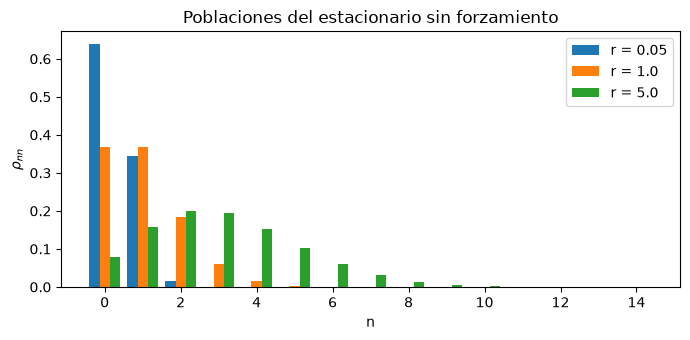

In [6]:
d = 40
fig, ax = plt.subplots(figsize=(7, 3.5))
for r, desp in zip([0.05, 1.0, 5.0], [-0.27, 0, 0.27]):
    H, c_ops, a = vdp(d, kp=r, km=1.0)
    p = np.diag(qt.steadystate(H, c_ops).full()).real
    ax.bar(np.arange(15) + desp, p[:15], width=0.27, label=f"r = {r}")
ax.set_xlabel("n"); ax.set_ylabel(r"$\rho_{nn}$"); ax.legend()
ax.set_title("Poblaciones del estacionario sin forzamiento")
plt.tight_layout(); plt.show()

## 4. El Liouvilliano y su espectro

`qt.liouvillian(H, c_ops)` da la supermatriz $d^2 \times d^2$. QuTiP también apila columnas (`qt.operator_to_vector` es `vecFLS`), así que el elemento $\rho_{nm}$ está en la posición $n + d\,m$ y la matriz es la misma que la de `liouvilliano` (comprobado contra Mathematica en la sección 9).

Si se ordena por sectores $k = n - m$, como en `ordenPorSectores`, se ve la estructura de bloques. Sin forzamiento es diagonal por bloques. El forzamiento conecta $k$ con $k \pm 1$.

vec apila columnas: True


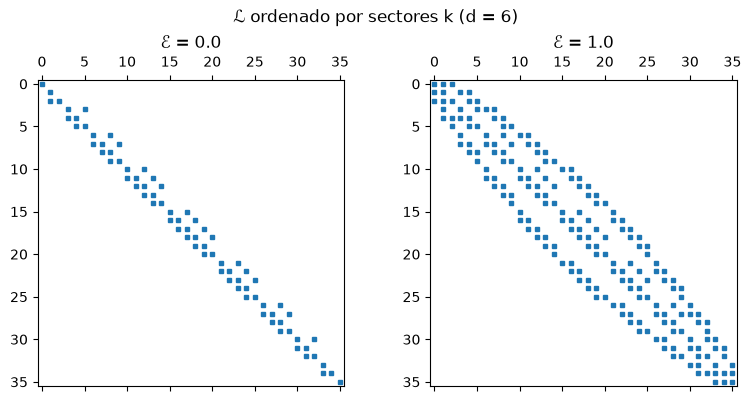

In [7]:
def orden_por_sectores(d):
    "Posiciones de vec(ρ) para k = -(d-1), …, d-1 y, dentro de cada sector, n creciente."
    pos, sector = [], []
    for k in range(-(d - 1), d):
        for n in range(d):
            m = n - k
            if 0 <= m < d:
                pos.append(n + d * m)
                sector.append(k)
    return np.array(pos), np.array(sector)

# comprobación del apilado por columnas
R = qt.rand_dm(3)
print("vec apila columnas:", np.allclose(qt.operator_to_vector(R).full().ravel(), R.full().ravel(order="F")))

d = 6
o, _ = orden_por_sectores(d)
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
for ax, E in zip(axs, [0.0, 1.0]):
    H, c_ops, a = vdp(d, 1.0, 20.0, E=E)
    L = qt.liouvillian(H, c_ops).full()
    ax.spy(L[np.ix_(o, o)], markersize=3)
    ax.set_title(f"ℰ = {E}")
plt.suptitle("ℒ ordenado por sectores k (d = 6)")
plt.tight_layout(); plt.show()

Sin forzamiento, los autovalores se pueden separar por sector. Hay un autovalor $0$ en $k = 0$, que es el estacionario. El autovalor de $k = \pm1$ más cercano a cero (su parte real) fija lo rápido que se pierde la fase, es decir, la difusión de fase.

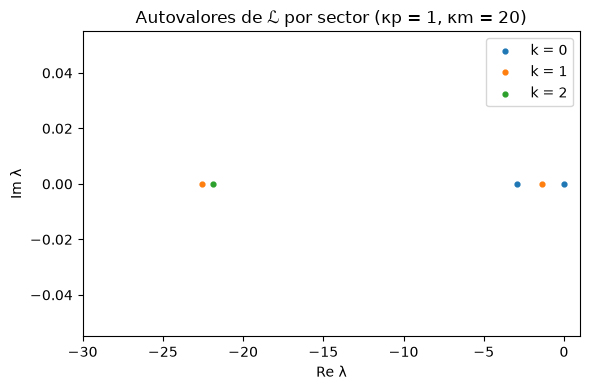

k = 0: autovalor más lento = -0.000000+0.000000j
k = 1: autovalor más lento = -1.361011+0.000000j
k = 2: autovalor más lento = -21.904091+0.000000j


In [8]:
d = 20
H, c_ops, a = vdp(d, kp=1.0, km=20.0)
L = qt.liouvillian(H, c_ops).full()
o, sec = orden_por_sectores(d)
Lo = L[np.ix_(o, o)]

fig, ax = plt.subplots(figsize=(6, 4))
lento = {}
for k in [0, 1, 2]:
    idx = np.where(sec == k)[0]
    ev = np.linalg.eigvals(Lo[np.ix_(idx, idx)])
    lento[k] = ev[np.argmax(ev.real)]
    ax.scatter(ev.real, ev.imag, s=12, label=f"k = {k}")
ax.set_xlim(-30, 1); ax.set_xlabel("Re λ"); ax.set_ylabel("Im λ"); ax.legend()
ax.set_title("Autovalores de ℒ por sector (κp = 1, κm = 20)")
plt.tight_layout(); plt.show()
for k, l in lento.items():
    print(f"k = {k}: autovalor más lento = {l:.6f}")

## 5. Dinámica: `mesolve`

`qt.mesolve(H, ρ0, t, c_ops, e_ops=[...])` integra la ecuación de Lindblad y devuelve los valores esperados en cada instante. Aquí se parte del vacío. Con forzamiento, $\langle a\rangle$ (el sector $k = 1$) deja de ser nulo: la fase se engancha.

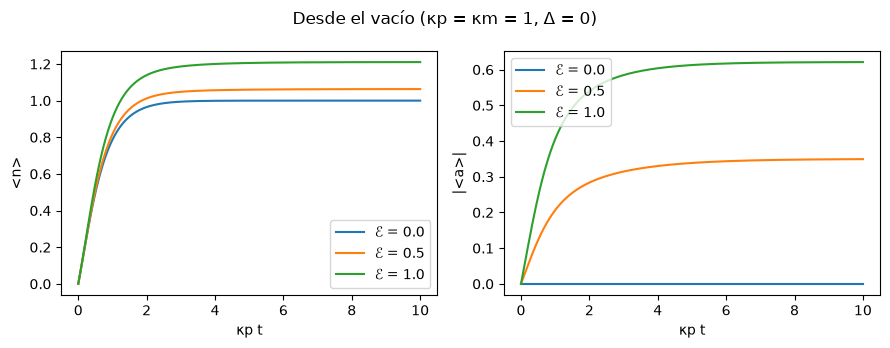

In [9]:
d = 15
t = np.linspace(0, 10, 300)
rho0 = qt.ket2dm(qt.basis(d, 0))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
for E in [0.0, 0.5, 1.0]:
    H, c_ops, a = vdp(d, kp=1.0, km=1.0, E=E)
    res = qt.mesolve(H, rho0, t, c_ops, e_ops=[a.dag() * a, a])
    axs[0].plot(t, res.expect[0].real, label=f"ℰ = {E}")
    axs[1].plot(t, np.abs(res.expect[1]), label=f"ℰ = {E}")
axs[0].set_ylabel("<n>"); axs[1].set_ylabel("|<a>|")
for ax in axs:
    ax.set_xlabel("κp t"); ax.legend()
plt.suptitle("Desde el vacío (κp = κm = 1, Δ = 0)")
plt.tight_layout(); plt.show()

## 6. Distribución de fase

QuTiP no trae la representación de fase de las notas, pero sale directamente de $\rho$:

$$P(\theta) = \frac{K(\theta,\theta)}{2\pi} = \frac{1}{2\pi}\sum_{n,m}\rho_{nm}\, e^{-i(n-m)\theta}$$

Es `distribucionFase`. Se usan los parámetros de `val20` de `vdp_forzado_fase.nb`: κp = 1, κm = 20 y Δ = 0, con varios ℰ.

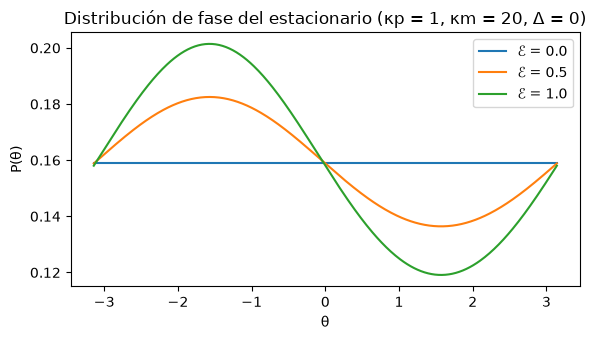

In [10]:
def distribucion_fase(rho, theta):
    "P(θ) = K(θ, θ)/2π con K(θ, θ') = Σ ρ_nm e^{-inθ} e^{imθ'}."
    R = rho.full()
    n = np.arange(R.shape[0])
    k = n[:, None] - n[None, :]
    return np.real(np.exp(-1j * k[None] * theta[:, None, None]) * R[None]).sum(axis=(1, 2)) / (2 * np.pi)

theta = np.linspace(-np.pi, np.pi, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
for E in [0.0, 0.5, 1.0]:
    H, c_ops, a = vdp(10, kp=1.0, km=20.0, E=E)
    ax.plot(theta, distribucion_fase(qt.steadystate(H, c_ops), theta), label=f"ℰ = {E}")
ax.set_xlabel("θ"); ax.set_ylabel("P(θ)"); ax.legend()
ax.set_title("Distribución de fase del estacionario (κp = 1, κm = 20, Δ = 0)")
plt.tight_layout(); plt.show()

## 7. Correlación a dos tiempos

`qt.correlation_2op_1t(H, None, τ, c_ops, A, B)` calcula $\langle A(\tau)B(0)\rangle$ en el estacionario (eso indica el `None`). Por la regresión cuántica, $\langle a^\dagger(\tau)a(0)\rangle$ evoluciona con el bloque $k = \pm1$ de $\mathcal{L}$. Su decaimiento a tiempos largos tiene que dar el autovalor más lento de ese sector (sección 4).

pendiente de log|g1| a τ grande: -1.360871
Re λ más lento del sector k = 1: -1.361011


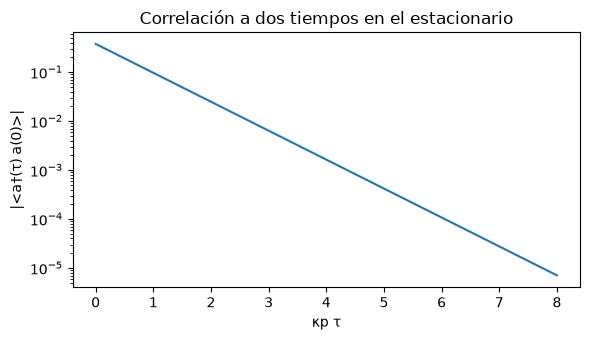

In [11]:
d = 20
H, c_ops, a = vdp(d, kp=1.0, km=20.0)
tau = np.linspace(0, 8, 400)
g1 = qt.correlation_2op_1t(H, None, tau, c_ops, a.dag(), a)

pend = np.polyfit(tau[200:], np.log(np.abs(g1[200:])), 1)[0]
print("pendiente de log|g1| a τ grande:", round(pend, 6))
print("Re λ más lento del sector k = 1:", round(lento[1].real, 6))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(tau, np.abs(g1))
ax.set_xlabel("κp τ"); ax.set_ylabel("|<a†(τ) a(0)>|")
ax.set_title("Correlación a dos tiempos en el estacionario")
plt.tight_layout(); plt.show()

## 8. Dos osciladores con acoplo disipativo

Para dos osciladores, los operadores se construyen con `qt.tensor`: $a_1 = a \otimes 1$ y $a_2 = 1 \otimes a$. El modelo es el de `vdp_dos_osciladores_fase.nb`, con el acoplo $\gamma_c\,\mathcal{D}[a_1 + a_2]$, $r = \kappa_p/\kappa_m$ y $c = \gamma_c/\kappa_p$:

$$\dot\rho = \sum_{j=1,2}\left(\kappa_p\,\mathcal{D}[a_j^\dagger] + \kappa_m\,\mathcal{D}[a_j^2]\right)\rho + \gamma_c\,\mathcal{D}[a_1 + a_2]\rho$$

Como medida de la sincronización se usa la coherencia normalizada $|\langle a_1^\dagger a_2\rangle| / \sqrt{\langle n_1\rangle\langle n_2\rangle}$ en el estacionario.

In [12]:
def dos_vdp(d, kp, km, gc):
    a = qt.destroy(d); I = qt.qeye(d)
    a1, a2 = qt.tensor(a, I), qt.tensor(I, a)
    c_ops = [np.sqrt(kp) * a1.dag(), np.sqrt(kp) * a2.dag(),
             np.sqrt(km) * a1 * a1, np.sqrt(km) * a2 * a2,
             np.sqrt(gc) * (a1 + a2)]
    H = 0 * a1.dag() * a1
    return H, c_ops, a1, a2

d, kp, km = 6, 1.0, 20.0   # r = 0.05
for c in [0.0, 0.5, 2.0, 10.0]:
    H, c_ops, a1, a2 = dos_vdp(d, kp, km, gc=c * kp)
    rho = qt.steadystate(H, c_ops)
    n1, n2 = qt.expect(a1.dag() * a1, rho), qt.expect(a2.dag() * a2, rho)
    C = qt.expect(a1.dag() * a2, rho)
    print(f"c = {c:4}:  <n1> = {n1:.4f}   <a1† a2> = {C.real:+.4f}   normalizada = {abs(C)/np.sqrt(n1*n2):.4f}")

c =  0.0:  <n1> = 0.3766   <a1† a2> = +0.0000   normalizada = 0.0000
c =  0.5:  <n1> = 0.3283   <a1† a2> = -0.0294   normalizada = 0.0896
c =  2.0:  <n1> = 0.2597   <a1† a2> = -0.0840   normalizada = 0.3236
c = 10.0:  <n1> = 0.2023   <a1† a2> = -0.1531   normalizada = 0.7569


## 9. Comprobación contra Mathematica y equivalencias

Para κp = 1, κm = 20, Δ = 0, ℰ = 1 y d = 10 (los parámetros de `val20`), se calcularon $\mathcal{L}$, $\rho_{ss}$ y $P(\theta)$ con `RepresentacionFase.wl` y con QuTiP. El resultado se resume debajo, en la celda de texto *Resultado de la comparación*.

| Mathematica (`RepresentacionFase.wl`) | QuTiP |
|---|---|
| `matrizFock[a, d]` | `qt.destroy(d)` |
| `ad`, `a ** a` | `a.dag()`, `a * a` |
| saltos `{{κ, L}, …}` | `c_ops = [np.sqrt(κ) * L, …]` |
| `liouvilliano[H, saltos, d]` | `qt.liouvillian(H, c_ops)` |
| `vecFLS[ρ]`, `matrizDeVec[v, d]` | `qt.operator_to_vector(ρ)`, `qt.vector_to_operator(v)` |
| `estadoEstacionario[ℒ, d]` | `qt.steadystate(H, c_ops)` |
| `distribucionFase[ρ]` | `distribucion_fase(ρ, θ)` de este cuaderno |
| evolución temporal | `qt.mesolve(H, ρ0, t, c_ops, e_ops)` |
| correlación a dos tiempos | `qt.correlation_2op_1t(H, None, τ, c_ops, A, B)` |
| dos osciladores | `qt.tensor(a, qt.qeye(d))`, … |

La diferencia práctica es que QuTiP solo trabaja con números. La parte simbólica (las EDOs por sector, la generatriz, las series en $r$) sigue siendo trabajo de Mathematica. QuTiP sirve para comprobarla y para ir a $d$ grandes.

In [13]:
# Datos de referencia para la comparación con Mathematica (sección 9)
H, c_ops, a = vdp(10, kp=1.0, km=20.0, E=1.0)
rho_val20 = qt.steadystate(H, c_ops)
np.set_printoptions(precision=12, suppress=True)
print("ρ00, ρ11, ρ22 =", np.diag(rho_val20.full())[:3].real)
print("ρ10 =", rho_val20.full()[1, 0])
print("P(0), P(π/2) =", distribucion_fase(rho_val20, np.array([0.0, np.pi / 2])))

ρ00, ρ11, ρ22 = [0.608453496509 0.373126393089 0.017967804016]
ρ10 = -0.11025866412667812j
P(0), P(π/2) = [0.158034229527 0.119114831135]


**Resultado de la comparación** (19-11-2026, Mathematica con `RepresentacionFase.wl` frente a QuTiP 5.3.1, val20 con d = 10):

- $\mathcal{L}$: la máxima diferencia elemento a elemento es $4.5\cdot10^{-13}$, sobre elementos de hasta $1440$. Es solo redondeo: `liouvilliano` y `qt.liouvillian` dan la misma matriz, con el mismo orden de $\mathrm{vec}(\rho)$.
- $\rho_{ss}$: la máxima diferencia es $3\cdot10^{-16}$.
- $\rho_{00}, \rho_{11}, \rho_{22}$, $\rho_{10}$, $P(0)$ y $P(\pi/2)$ coinciden en las 12 cifras impresas en la celda anterior.